## IMPORTAÇÕES

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import curve_fit

##POTENCIAL DE ESTUDO

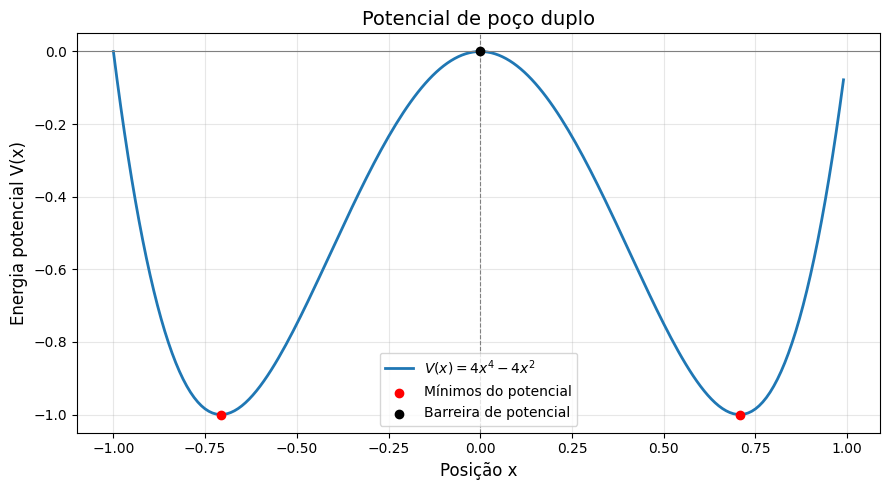

In [31]:
xteste = np.arange(-1, 1, 0.01)
Vteste = 4*xteste**4 - 4*xteste**2

plt.figure(figsize=(9, 5))

plt.plot(xteste, Vteste, label=r'$V(x)=4x^4-4x^2$', linewidth=2)

# Mínimos do potencial
plt.scatter([-1/np.sqrt(2), 1/np.sqrt(2)], [-1, -1],
            color='red', label='Mínimos do potencial', zorder=3)

# Barreira de potencial
plt.scatter([0], [0], color='black',
            label='Barreira de potencial', zorder=3)

plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8, linestyle='--')

plt.xlabel('Posição x', fontsize=12)
plt.ylabel('Energia potencial V(x)', fontsize=12)
plt.title('Potencial de poço duplo', fontsize=14)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## FUNÇÕES

In [5]:
#FUNÇÃO DO POTENCIAL DE POÇO DUPLO SEM RUIDO

dt = 0.001 #unidades naturais

def passo(x,p):
  p = p - dt*(16*x**3 -8*x)
  x = x + dt*p
  return x,p


#FUNÇÃO DA DINAMICA DE LANGEVIN EM POTENCIAL DE POÇOS DUPLOS

def passo_ruido(x,p):
  p = p - dt*(16*x**3 -8*x) - p*beta*dt + F*np.sqrt(dt)*np.random.normal(0,1)
  x = x + dt*p
  return x,p


##VALORES DO EXPERIMENTO

In [27]:
#VALORES DO EXPERIMENTO
lista_porcentagem = ["100%","75%","50%","25%","10%"]
intensidade_aleatoria = [1.5,1.25,0.99,0.68,0.42] #INTENSIDADE DAS FORÇAS
dt = 0.001
beta = 1 #COEFICIENTE DE ATRITO
exp = 500 #NUMERO DE EXPERIMENTOS
passos = 20000 #NUMERO DE PASSOS EM CADA EXPERIMENTO
t = np.arange(passos)*dt
tempo_pp = np.zeros((len(forcas), exp))

## TESTE DE FORÇA ALEATÓRIO PARA A ENERGIA MÉDIA ALCANÇADA DA PARTICULA

100%|██████████| 500/500 [00:31<00:00, 16.03it/s]


error= 0.03515407490531019
med= -0.01833276648045592


100%|██████████| 500/500 [00:29<00:00, 17.12it/s]


error= 0.0225043060405533
med= -0.279474071475157


100%|██████████| 500/500 [00:30<00:00, 16.66it/s]


error= 0.011072158707429652
med= -0.49125647027137875


100%|██████████| 500/500 [00:29<00:00, 16.92it/s]


error= 0.008752477232820379
med= -0.7643552678130868


100%|██████████| 500/500 [00:30<00:00, 16.49it/s]


error= 0.0022582331802724143
med= -0.9126330055842397


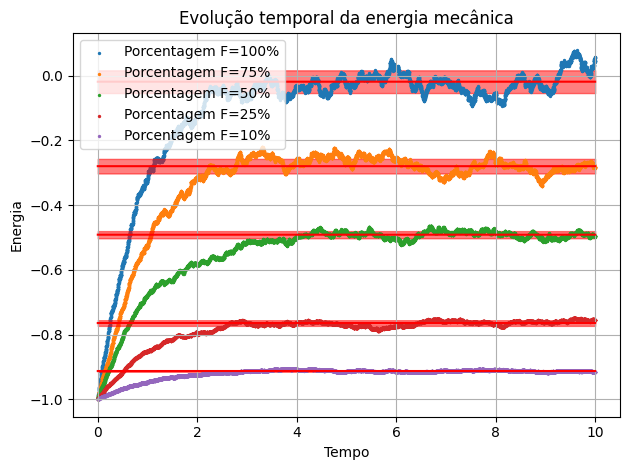

In [52]:
for forca in range(len(intensidade_aleatoria)):
  F=intensidade_aleatoria[forca]
  t=np.arange(passos)*dt
  xmed=np.zeros(passos)
  pmed=np.zeros(passos)
  Kmed=np.zeros(passos)
  Vmed=np.zeros(passos)
  xpmed=np.zeros(passos)

  for experimento in tqdm(range(exp)):
    xarray = np.zeros(passos)
    parray = np.zeros(passos)
    Karray = np.zeros(passos)
    Varray = np.zeros(passos)
    xarray[0] = -1/np.sqrt(2)
    Varray[0] = 4*xarray[0]**4-4*xarray[0]**2

    for step in range(passos-1):
      xarray[step+1],parray[step+1] = passo_ruido(xarray[step],parray[step])
      Karray[step+1] = 0.5*parray[step+1]**2
      Varray[step+1] = 4*xarray[step+1]**4-4*xarray[step+1]**2

    xparray = xarray*parray
    xpmed += xparray
    xmed += xarray
    pmed += parray
    Kmed += Karray
    Vmed += Varray

  xmed = xmed/exp
  pmed = pmed/exp
  Kmed = Kmed/exp
  Vmed = Vmed/exp
  xpmed = xpmed/exp

  med = Kmed[5000:]+Vmed[5000:]
  error=np.std(med)
  print('error=', error)
  med = np.mean(med)
  print('med=', med)


  plt.fill_between(t, (med-error)*np.ones(len(t)), (med+error)*np.ones(len(t)), alpha=0.5, color='red')
  plt.scatter(t,Kmed+Vmed,s=2, label=f'Porcentagem F={lista_porcentagem[forca]}')
  plt.plot(t, med*np.ones(len(t)), color='red')
  plt.legend()
  plt.title('Evolução temporal da energia mecânica')
  plt.xlabel('Tempo')
  plt.ylabel('Energia')
  plt.tight_layout()
  plt.grid()

##TEMPO ACUMULATIVO

In [28]:
for i, F in enumerate(intensidade_aleatoria):

  for exps in tqdm(range(exp)):

    xarray = np.zeros(passos)
    parray = np.zeros(passos)
    xarray[0] = -1/np.sqrt(2)

    tempo_experimento = 0
    caixa_atual = -1
    caixa = -1
    passou = 0

    for step in range(passos-1):

      xarray[step+1], parray[step+1] = passo_ruido(
          xarray[step], parray[step]
      )

      if xarray[step+1] <= 0:
        caixa_atual = -1
      else:
        caixa_atual = 1

      if caixa == caixa_atual:
        if passou == 0:
          tempo_experimento += 1

      else:
        caixa = caixa_atual

        if passou == 0:
          tempo_experimento += 1
          tempo_pp[i, exps] = tempo_experimento*dt
          passou = 1

100%|██████████| 500/500 [00:46<00:00, 10.67it/s]


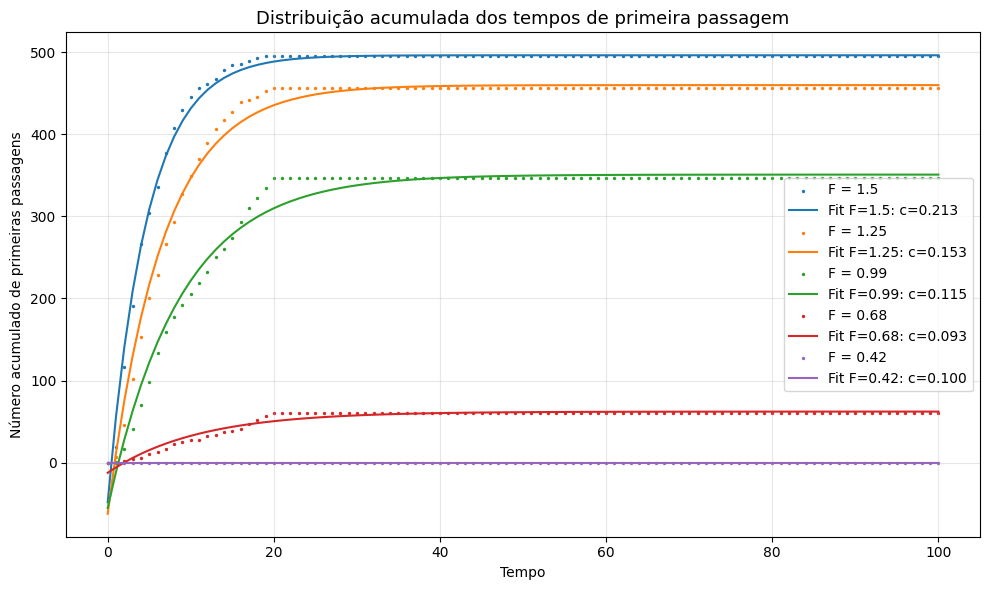

In [49]:
def func(x, a, b, c):
    return a - b * np.exp(-c*x)

plt.figure(figsize=(10, 6))

for i, F in enumerate(intensidade_aleatoria):

    PP_time = np.zeros(101)

    for cat in range(101):
        tt = tempo_pp[i]
        tt = tt[tt > 0]
        tt = tt[tt < cat]
        PP_time[cat] = len(tt)

    x = np.arange(101)

    plt.scatter(x, PP_time, s=2, label=f'F = {F}')

    popt, pcov = curve_fit(func, x, PP_time, p0=[exps, exps, 0.1], maxfev=10000)

    plt.plot(x, func(x, *popt), label=f'Fit F={F}: c={popt[2]:.3f}')

plt.title('Distribuição acumulada dos tempos de primeira passagem', fontsize=13)
plt.xlabel('Tempo')
plt.ylabel('Número acumulado de primeiras passagens')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

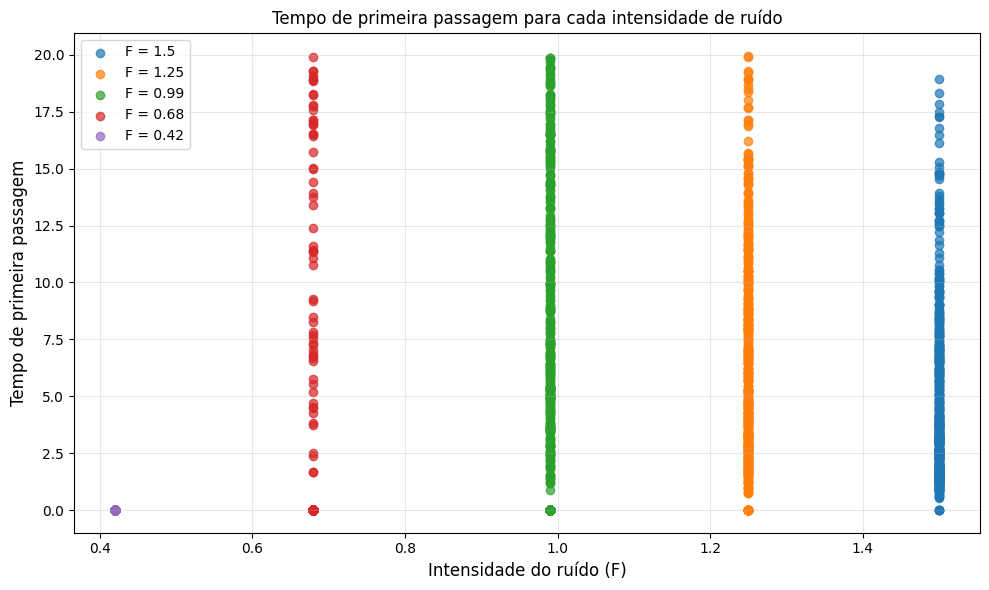

In [51]:
plt.figure(figsize=(10, 6))

for i, F in enumerate(intensidade_aleatoria):

    plt.scatter(
        np.full(exp, F),
        tempo_pp[i, :],
        label=f'F = {F}',
        alpha=0.7
    )

plt.xlabel('Intensidade do ruído (F)', fontsize=12)
plt.ylabel('Tempo de primeira passagem', fontsize=12)
plt.title('Tempo de primeira passagem para cada intensidade de ruído')

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()